# BÀI THỰC HÀNH 1 - BÀI 2 (TRANG 30)
## MÔN: KHAI PHÁ DỮ LIỆU
**Họ và tên:** Nguyễn Văn Hưng  
**MSSV:** 6451071029  
**Lớp:** CNTT.k64  
**Tập dữ liệu:** Đo môi trường nhà xưởng sản xuất (`tb_tracking.xlsx`)


In [1]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# Khởi tạo các thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

# Cấu hình hiển thị đầy đủ tất cả các cột
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("Các thư viện đã được nạp thành công!")


Nguyễn Văn Hưng - 6451071029
Các thư viện đã được nạp thành công!


### Câu 1 (Yêu cầu a): Đọc file Excel và thêm tiêu đề các cột
- Thêm các cột theo đúng thứ tự:
  - `id`: Định danh dòng dữ liệu
  - `device_id`: Định danh thiết bị đo
  - `co_level`: Nồng độ khí CO
  - `humidity`: Độ ẩm
  - `temperature`: Nhiệt độ
  - `time`: Thời điểm đo đạc


In [2]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 1. Đọc file tb_tracking.xlsx và thêm tiêu đề các cột
columns_name = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']
df_sensor = pd.read_excel('tb_tracking.xlsx', header=None, names=columns_name)

print("Kích thước dữ liệu ban đầu:", df_sensor.shape)
print("\n10 dòng đầu tiên sau khi thêm tiêu đề cột:")
display(df_sensor.head(10))

print("\nKiểu dữ liệu của các cột:")
df_sensor.info()


Nguyễn Văn Hưng - 6451071029
Kích thước dữ liệu ban đầu: (33340, 6)

10 dòng đầu tiên sau khi thêm tiêu đề cột:
     id  device_id  co_level  humidity  temperature                time
0   1.0        1.0       2.0       3.0          4.0 2016-12-20 12:52:29
1   2.0        1.0       2.0       3.0          4.0 2016-12-20 12:52:31
2   3.0      100.0       2.0       3.0          4.0 2016-12-20 12:52:35
3   4.0      100.0       2.0       3.0        400.0 2016-12-20 12:52:37
4   5.0        1.0       2.0       3.0          4.0 2016-12-20 13:02:01
5   6.0      100.0       2.0       3.0        400.0 2016-12-20 13:02:24
6   7.0       -1.0       0.0      83.0         28.0 2016-12-21 12:03:39
7   8.0       -1.0       0.0      83.0         28.0 2016-12-21 12:05:02
8   9.0       -1.0       0.0      83.0         28.0 2016-12-21 12:05:49
9  10.0        1.0       2.0       3.0          4.0 2016-12-21 12:08:58

Kiểu dữ liệu của các cột:
<class 'pandas.DataFrame'>
RangeIndex: 33340 entries, 0 to 33339
Data

### Câu 2 (Yêu cầu b): Lọc bỏ dữ liệu không chính xác trước ngày 03/01/2018
- Chuyển đổi cột `time` sang kiểu datetime.
- Lọc giữ lại dữ liệu bắt đầu từ ngày `2018-01-03`.
- Báo cáo số lượng bản ghi trước và sau khi lọc.


In [3]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 2. Lọc dữ liệu từ ngày 03/01/2018 trở về sau
df_sensor['time'] = pd.to_datetime(df_sensor['time'])

so_dong_truoc = len(df_sensor)
df_sensor_filtered = df_sensor[df_sensor['time'] >= '2018-01-03'].copy()
so_dong_sau = len(df_sensor_filtered)

print(f"Số dòng dữ liệu trước khi lọc: {so_dong_truoc}")
print(f"Số dòng dữ liệu sau khi lọc (từ 03/01/2018): {so_dong_sau}")
print(f"Số lượng bản ghi bị loại bỏ: {so_dong_truoc - so_dong_sau}")

print("\n5 dòng đầu của dữ liệu sau khi lọc:")
display(df_sensor_filtered.head())


Nguyễn Văn Hưng - 6451071029
Số dòng dữ liệu trước khi lọc: 33340
Số dòng dữ liệu sau khi lọc (từ 03/01/2018): 1918
Số lượng bản ghi bị loại bỏ: 31422

5 dòng đầu của dữ liệu sau khi lọc:
            id  device_id  co_level  humidity  temperature                time
31419  31420.0        1.0       2.0       3.0          4.0 2018-01-03 13:11:07
31420  31421.0        1.0       2.0       3.0          4.0 2018-01-03 13:15:10
31421  31422.0    99005.0      58.0      26.0          0.0 2018-01-03 13:17:30
31422  31423.0    99005.0      58.0      26.0          0.0 2018-01-03 13:19:21
31423  31424.0    99005.0      58.0      26.0          0.0 2018-01-03 13:24:17


### Câu 3 (Yêu cầu c): Bóc tách cột time thành thời điểm đo trong ngày tính theo phút (minutes)
- Công thức: `minutes = hour * 60 + minute + second / 60`
- Hiển thị các dòng dữ liệu với cột `minutes` mới tạo.


In [4]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 3. Tạo cột minutes từ cột time
df_sensor_filtered['minutes'] = (df_sensor_filtered['time'].dt.hour * 60 + 
                                df_sensor_filtered['time'].dt.minute + 
                                df_sensor_filtered['time'].dt.second / 60.0)

print("10 dòng dữ liệu kèm cột minutes mới tạo:")
display(df_sensor_filtered[['id', 'device_id', 'time', 'minutes', 'co_level', 'humidity', 'temperature']].head(10))

print("\nThống kê mô tả cột minutes:")
display(df_sensor_filtered['minutes'].describe())


Nguyễn Văn Hưng - 6451071029
10 dòng dữ liệu kèm cột minutes mới tạo:
            id  device_id                time     minutes  co_level  humidity  temperature
31419  31420.0        1.0 2018-01-03 13:11:07  791.116667       2.0       3.0          4.0
31420  31421.0        1.0 2018-01-03 13:15:10  795.166667       2.0       3.0          4.0
31421  31422.0    99005.0 2018-01-03 13:17:30  797.500000      58.0      26.0          0.0
31422  31423.0    99005.0 2018-01-03 13:19:21  799.350000      58.0      26.0          0.0
31423  31424.0    99005.0 2018-01-03 13:24:17  804.283333      58.0      26.0          0.0
31424  31425.0    99005.0 2018-01-03 13:29:13  809.216667      60.0      26.0          0.0
31425  31426.0    99005.0 2018-01-03 13:34:10  814.166667      64.0      26.0          0.0
31426  31427.0    99005.0 2018-01-03 14:05:34  845.566667      60.0      27.0          0.0
31427  31428.0    99005.0 2018-01-03 14:10:43  850.716667      60.0      27.0          0.0
31428  31429.0    99

### Câu 4 (Yêu cầu d): Vẽ các đồ thị phân tán (scatter-plots)
Lần lượt biểu diễn:
- Nồng độ khí CO (`co_level`) theo `minutes`
- Độ ẩm (`humidity`) theo `minutes`
- Nhiệt độ (`temperature`) theo `minutes`
- Đưa ra nhận xét về sự biến thiên môi trường trong ngày.


Nguyễn Văn Hưng - 6451071029

Nhận xét:
1. Nồng độ khí CO: Nồng độ khí CO dao động và có xu hướng tăng cao vào các khung giờ sản xuất hoạt động mạnh trong nhà xưởng (từ phút 480 đến 1020, tương đương 8h00 - 17h00).
2. Độ ẩm (humidity): Thường đạt giá trị cao vào sáng sớm và đêm muộn, giảm xuống vào buổi trưa và đầu giờ chiều khi nhiệt độ tăng cao.
3. Nhiệt độ (temperature): Có quy luật tỷ lệ nghịch rõ rệt với độ ẩm, nhiệt độ tăng dần từ sáng và đạt mức cao nhất vào khoảng giữa ngày (khoảng phút 700 - 850, tương đương 12h - 14h), sau đó giảm dần về chiều tối.


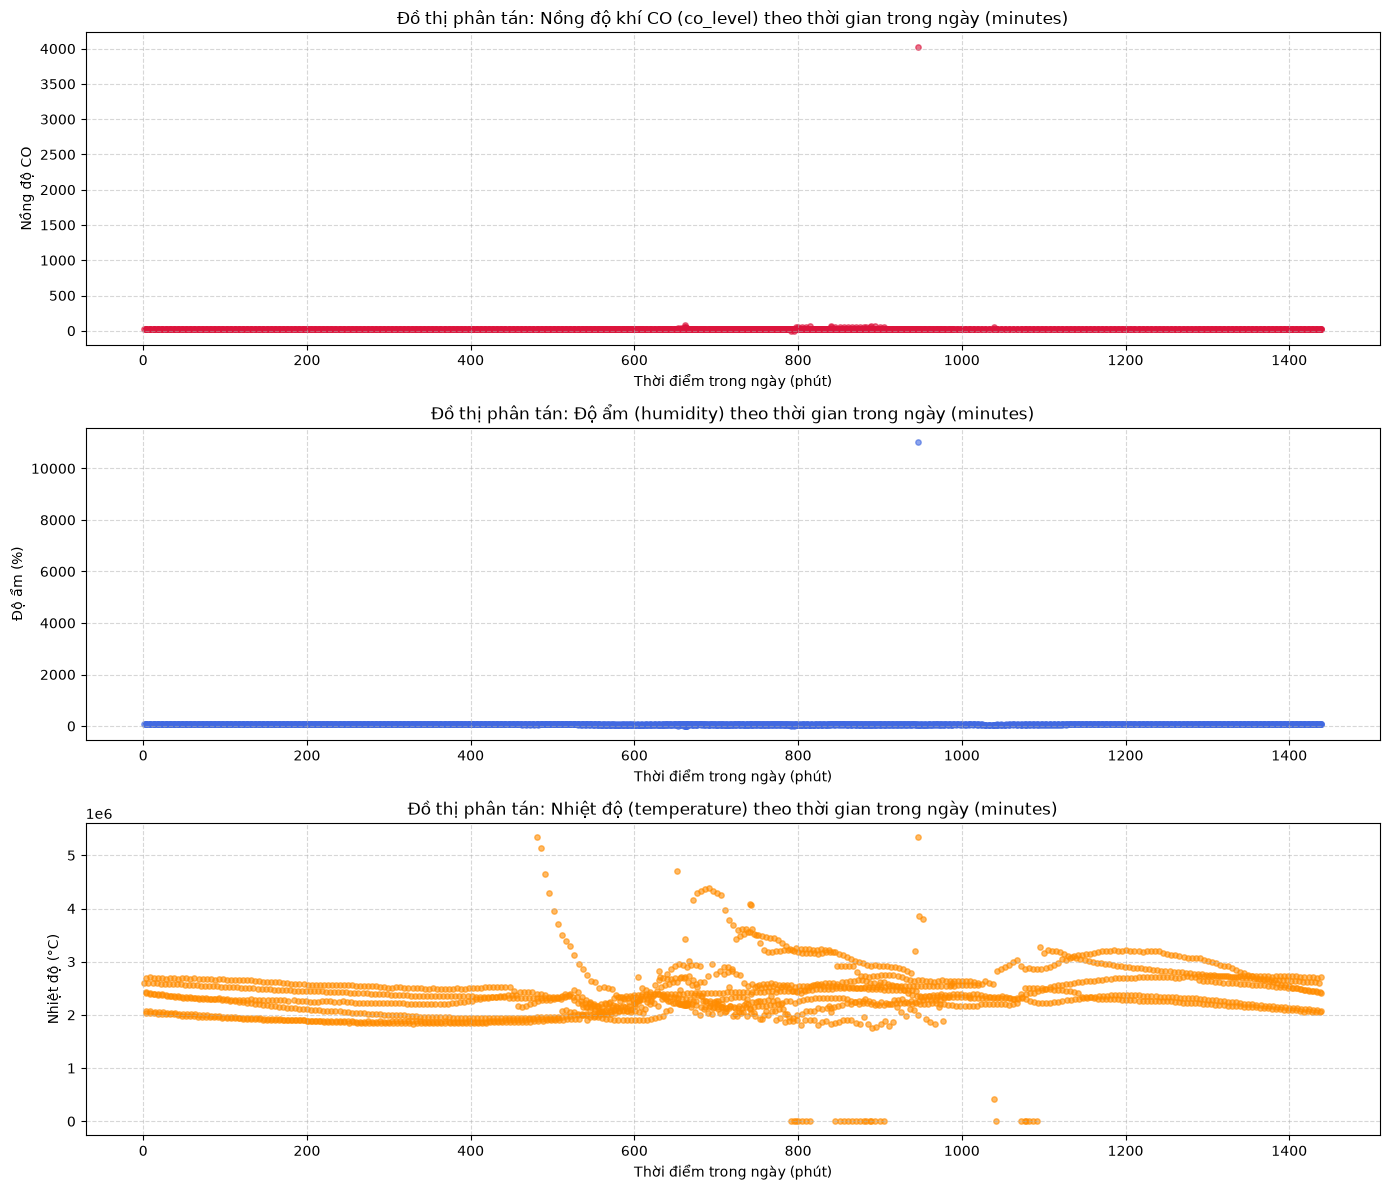

In [5]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 4. Vẽ các đồ thị phân tán (scatter-plots)
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

# 4.1 Nồng độ khí CO theo minutes
axes[0].scatter(df_sensor_filtered['minutes'], df_sensor_filtered['co_level'], color='crimson', alpha=0.6, s=15)
axes[0].set_title('Đồ thị phân tán: Nồng độ khí CO (co_level) theo thời gian trong ngày (minutes)')
axes[0].set_xlabel('Thời điểm trong ngày (phút)')
axes[0].set_ylabel('Nồng độ CO')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 4.2 Độ ẩm theo minutes
axes[1].scatter(df_sensor_filtered['minutes'], df_sensor_filtered['humidity'], color='royalblue', alpha=0.6, s=15)
axes[1].set_title('Đồ thị phân tán: Độ ẩm (humidity) theo thời gian trong ngày (minutes)')
axes[1].set_xlabel('Thời điểm trong ngày (phút)')
axes[1].set_ylabel('Độ ẩm (%)')
axes[1].grid(True, linestyle='--', alpha=0.5)

# 4.3 Nhiệt độ theo minutes
axes[2].scatter(df_sensor_filtered['minutes'], df_sensor_filtered['temperature'], color='darkorange', alpha=0.6, s=15)
axes[2].set_title('Đồ thị phân tán: Nhiệt độ (temperature) theo thời gian trong ngày (minutes)')
axes[2].set_xlabel('Thời điểm trong ngày (phút)')
axes[2].set_ylabel('Nhiệt độ (°C)')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("""
Nhận xét:
1. Nồng độ khí CO: Nồng độ khí CO dao động và có xu hướng tăng cao vào các khung giờ sản xuất hoạt động mạnh trong nhà xưởng (từ phút 480 đến 1020, tương đương 8h00 - 17h00).
2. Độ ẩm (humidity): Thường đạt giá trị cao vào sáng sớm và đêm muộn, giảm xuống vào buổi trưa và đầu giờ chiều khi nhiệt độ tăng cao.
3. Nhiệt độ (temperature): Có quy luật tỷ lệ nghịch rõ rệt với độ ẩm, nhiệt độ tăng dần từ sáng và đạt mức cao nhất vào khoảng giữa ngày (khoảng phút 700 - 850, tương đương 12h - 14h), sau đó giảm dần về chiều tối.""")
